# To be completed at the Data Science Workshop and in your own time.

These set of examples we will help you get familiar with estimating probabilities and using Bayes Theorem within a Jupyter notebook.  The questions coloured green are important practice for CA.

Before attempting these examples, please ensure you have read through [Chapter 4 Jupyter Notebook](https://github.com/itrharrison/PX4146/blob/main/Chapter4/Chapter4.ipynb) and have completed the Learning Central **Chapter 4 quiz**.

These are good practice for CA 1 Question 5.

***

# Errors

## Question

Three students measure the same resistance several times, with final measurements (in Ohms):

Student 1: $R = 11 \pm 1$
Student 2: $R = 12 \pm 1$
Student 3: $R = 10 \pm 3$.

Given these three results what do we write down as the best estimate for the resistance $R$? Tip: you will need to use weighted errors.

### Answer

In [13]:
import numpy as np
#measurements
x = [11,12,10]
#uncergtainities
o = [1,1,3]
#weights
w = []
for m in o:
  q = 1/(m**2)
  w.append(q)
print(w)

#weighted average
x_o = 0
for i in range(3):
  #r = (w[i] * x[i]) / w[i]
  r = (w[i] * x[i])
  x_o += r

wo = np.sum(w)
x_oo = x_o/wo

print(x_oo)
#weighted std dev
o_x_o = 1/np.sqrt(wo)

print('The best estimate for resistance R is {:.3f}'.format(x_oo)+'and a standard deviation of {:.3f}'.format(o_x_o))

[1.0, 1.0, 0.1111111111111111]
11.421052631578947
The best estimate for resistance R is 11.421and a standard deviation of 0.688


***

# Correlation

## <font color=#30a64d>Question </font>

The datafile [worldpopulation.txt](https://github.com/itrharrison/PX4146/blob/main/Chapter4/worldpopulation.txt) contains the world population size measured since 1960. Plot the data (you will need to upload the datafile to your Google Colab). <br><br>

Measure the correlation coefficient using the in built Python package for the Pearson $r$s statistic. <br><br>

Measure it again but this time creating the functions to calculate $r$ from scratch.  

The url of the file is "https://github.com/itrharrison/PX4146/blob/main/Chapter4/worldpopulation.txt"

### Answer

Pearson correlation is 1.00 with a p value of 0.00


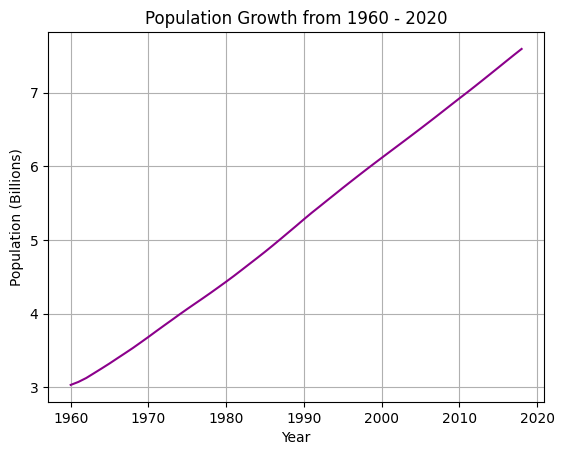

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

# open file
data = np.loadtxt('/content/worldpopulation.txt')
years = data[0]
pop = data[1]/1e9

#Pearson corelation coefficient
corr_pearson, p_pearson = pearsonr(years, pop)
print('Pearson correlation is {:.2f}'. format(corr_pearson)+ ' with a p value of {:.2f}'.format(p_pearson))

#r = p value
#Plot graph of population against time
plt.plot(years, pop, color ='darkmagenta')
plt.xlabel('Year')
plt.ylabel('Population (Billions)')
plt.title('Population Growth from 1960 - 2020')
plt.grid()
plt.show()

***

# Hypothesis Testing

## <font color=#30a64d>Question</font>

A company releases a new ski wax that it claims (naturally) is superior to its rivals, and greatly reduces the friction between skis and snow. A skiing magazine decides to test the claim by performing an experiment. They take 10 pairs of skis, and treat one ski from each pair -- the left one -- with the new wax, and the other (the right) ski with the wax from a competing brand. Each pair of skis are then released from the top of a ramp in turn, and they record which of the two skis reach the bottom of the ramp first.    The team find that the new skis win 8 of the 10 races.  Is their claim correct?

### Answer

The Null Hypothesis $H_o$: the new ski wax is not superior to rival ski wax.

The Alternative Hypothesis $H_1$: The new ski wax is superior to rival ski wax

Possible Outcomes: Reject $H_o$ or do not reject $H_1$

The result is statistically signficant if $P-value < 0.05$ (1 experiment in every 20 will yield incorrect conclusions) . (Reject Null Hypothesis) e.g. if $P$ = 0.03, the Null Hypothesis is rejected at a significant level.

Higher P-value than 0.05 is not significantally relevant and indicates strong evidence for the Null Hypothesis.

Binomial probability:For N trials, with a success probability of θ in each trial, PDF for getting 𝞶 successes (including the
possible combinations factor)

$B_{N, θ} = (N v)^Tθ^v(1-θ)^{N-v}$


In [12]:
import math
H_o = 1/2 # if ski waxes are equal, there's a 50/50 chance of either ski winning
T = 10 #Number of tests
W = 8 # Number of wins by new wax

# binomial
p_8 = (math.factorial(10)/(math.factorial(8)*math.factorial(10-8))) * (0.5)**8 * (0.5)**2 #probability of getting excatly 8 wins
p_9 = (math.factorial(10)/(math.factorial(9)*math.factorial(10-9)))* (0.5)**9 * (0.5)**1 #Probability of getting 9 wins
p_10 = (math.factorial(10)/(math.factorial(10)*math.factorial(10-10)))* (0.5)**10 * (0.5)**0 # Probability of getting exactly 10 wins

#P-value (Significance level)
print('P-values =',p_8 + p_9 + p_10)

P-values = 0.0546875


A p-value of 0.05 is considered statistically significant, so as 0.0547> 0.05, the result is not statistically significant and we are not able to reject the null hypothesis.